#### CBIM Problem Canvas ---- Retail Sales Pulse

#### 1.Situation(S)

The retail business currently has sales information from its 12 stores across Andhra Pradesh. Management has six months of historical sales data from January to June 2026, covering five product categories. In Part 1, this historical information is used to understand store performance, category performance, sales trends, and unusual drops in sales. In Part 2, the business receives the latest seven days of sales information through a weekly API/JSON response. Today, this information requires analysis to understand what is happening in the business.

#### 2. Complication(C)

The Operations Head does not have a quick and consistent way to identify where sales performance is becoming a concern. A store may suddenly perform below its normal level, or a product category may experience a significant decline, but these issues are difficult to identify quickly when information has to be reviewed manually. The Operations Head also needs to make promotional spending decisions based on evidence rather than assumptions. Repeating this analysis manually every Monday takes time and delays business action.


#### 3. Question(Q)

Which stores and product categories are performing below expectations, and where should the business take action? Part 1 should show the business's normal sales performance over the six-month period and highlight strong, weak, and unusual performance. Part 2 should show whether the latest week's sales are performing as expected compared with the historical baseline. Management should use this information to decide where promotional spending, operational attention, or further investigation is needed.

#### 4. SSOT

The historical CSV is the business's source of truth for past performance, while the weekly API/JSON is the source of truth for the latest performance. The CSV tells management what normal performance has looked like over the past six months. The weekly API/JSON tells management what is happening now. By comparing the latest weekly results with the historical baseline, the business can identify whether a current decline is significant and needs attention. In simple terms: CSV = historical business performance; API/JSON = current business performance.


#### 5. Success Definition

Part 1: The business should be able to clearly identify its best-performing and underperforming stores and categories and use those findings to support a specific management action. Part 2: The business should receive a weekly performance summary that clearly identifies important declines or alerts compared with historical performance, without waiting for manual analysis. The weekly category alert is triggered when revenue is more than 20% below the six-month daily average.

#### 6. Primary Stakeholder

The primary stakeholder is the Head of Retail Operations / Retail Management. They need to decide where to allocate promotional spending, which stores or categories require attention, and where further investigation may be needed. They need the historical analysis for broader planning decisions and the weekly update every Monday morning for current business decisions. The solution helps them move from manual review to timely, evidence-based action.

#### 5.1 - Load and inspect the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv(r"C:\Users\KEERTHI\Downloads\MUC01_Retail_Sales_Dataset.csv")
df

,transaction_id,date,store_id,store_city,category,product_name,units_sold,unit_price,revenue,discount_pct
0,TXN000001,2026-01-01,S01,Vijayawada,Electronics,Smart TV,2,3075.46,5843.37,5
1,TXN000002,2026-01-01,S01,Vijayawada,Electronics,Laptop,1,11598.06,11598.06,0
2,TXN000003,2026-01-01,S01,Vijayawada,Electronics,Tablet,3,5738.37,15493.60,10
3,TXN000004,2026-01-01,S01,Vijayawada,Electronics,Smart TV,3,3281.28,9351.65,5
4,TXN000005,2026-01-01,S01,Vijayawada,Apparel,Jeans,1,1917.14,1917.14,0
...,...,...,...,...,...,...,...,...,...,...
107831,TXN107832,2026-06-30,S12,Kakinada,Personal Care,Shampoo,4,803.64,3214.56,0
107832,TXN107833,2026-06-30,S12,Kakinada,Personal Care,Body Lotion,2,288.41,547.98,5
107833,TXN107834,2026-06-30,S12,Kakinada,Personal Care,Shampoo,2,808.72,1536.57,5
107834,TXN107835,2026-06-30,S12,Kakinada,Personal Care,Face Wash,5,237.13,1185.65,0


In [3]:
df.shape

(107836, 10)

In [4]:
df.columns

Index(['transaction_id', 'date', 'store_id', 'store_city', 'category',
       'product_name', 'units_sold', 'unit_price', 'revenue', 'discount_pct'],
      dtype='str')

In [5]:
df.dtypes

transaction_id        str
date                  str
store_id              str
store_city            str
category              str
product_name          str
units_sold          int64
unit_price        float64
revenue           float64
discount_pct        int64
dtype: object

In [6]:
df.isnull().sum()

transaction_id    0
date              0
store_id          0
store_city        0
category          0
product_name      0
units_sold        0
unit_price        0
revenue           0
discount_pct      0
dtype: int64

In [7]:
df.isnull().sum().sum()

np.int64(0)

In [8]:
df.describe()

,units_sold,unit_price,revenue,discount_pct
count,107836.000000,107836.000000,107836.000000,107836.000000
mean,2.583488,1778.097787,4263.920924,7.228152
std,1.471616,5053.631792,14243.244169,6.730445
min,1.000000,50.020000,40.040000,0.000000
25%,1.000000,274.827500,467.772500,0.000000
50%,2.000000,488.450000,1034.615000,5.000000
75%,3.000000,1039.522500,2473.335000,10.000000
max,13.000000,44990.140000,355090.880000,20.000000


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 107836 entries, 0 to 107835
Data columns (total 10 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   transaction_id  107836 non-null  str    
 1   date            107836 non-null  str    
 2   store_id        107836 non-null  str    
 3   store_city      107836 non-null  str    
 4   category        107836 non-null  str    
 5   product_name    107836 non-null  str    
 6   units_sold      107836 non-null  int64  
 7   unit_price      107836 non-null  float64
 8   revenue         107836 non-null  float64
 9   discount_pct    107836 non-null  int64  
dtypes: float64(2), int64(2), str(6)
memory usage: 13.2 MB


#### 5.1 Observations 

 The dataset contains six months of retail sales data from January to June 2026, including stores, product categories, units sold, prices, discounts, and revenue.The descriptive statistics give an overall view of the sales data and help understand how much the values vary across transactions.The dataset was checked for missing values and column data types before starting further analysis.

 ##### 5.2 - Revenue By Store

In [10]:
store_revenue = df.groupby(["store_id", "store_city"])["revenue"].sum()

store_revenue = store_revenue.sort_values(ascending=False)

store_revenue

store_id  store_city 
S01       Vijayawada     59055493.38
S03       Guntur         53175162.00
S07       Tirupati       48537659.56
S06       Rajahmundry    44969840.50
S02       Vijayawada     42069856.33
S04       Guntur         41379797.16
S08       Tirupati       35032561.12
S09       Nellore        33452441.09
S11       Kakinada       32780138.71
S05       Rajahmundry    25157347.02
S10       Nellore        22217399.05
S12       Kakinada       21976480.86
Name: revenue, dtype: float64

In [11]:
store_labels = store_revenue.index.get_level_values("store_id") + " - " + store_revenue.index.get_level_values("store_city")

In [12]:
colors = ["skyblue"] * len(store_revenue)

colors[:3] = ["green"] * 3
colors[-3:] = ["red"] * 3

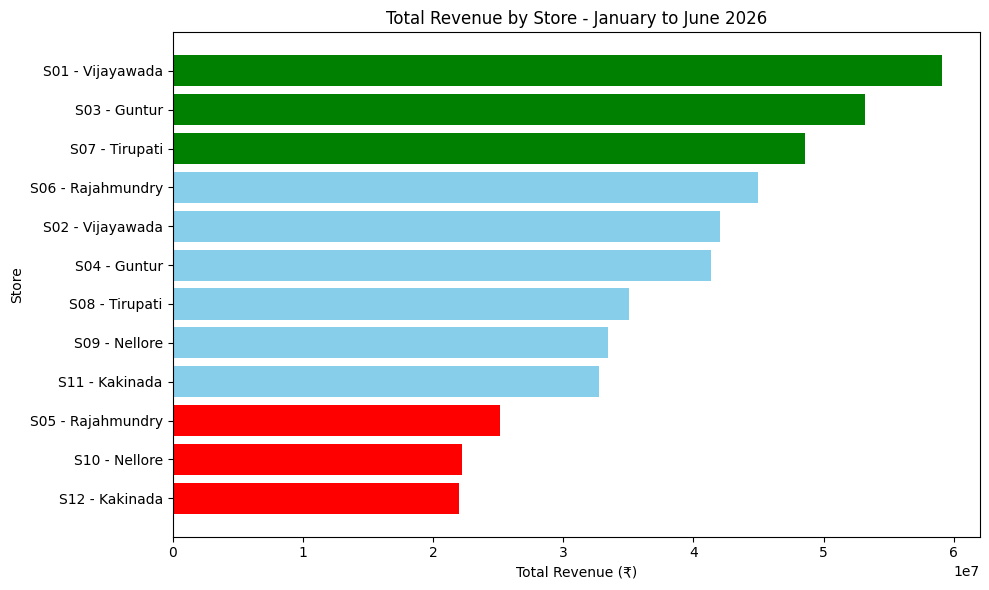

In [13]:
plt.figure(figsize=(10, 6))

plt.barh(store_labels, store_revenue.values, color=colors)

plt.xlabel("Total Revenue (₹)")
plt.ylabel("Store")
plt.title("Total Revenue by Store - January to June 2026")

plt.gca().invert_yaxis()

plt.tight_layout()

plt.show()

In [14]:
df.duplicated().sum()

np.int64(0)

#### 5.2 Business Interpretation

The top three stores Vijayawada,Guntur,Tirupsti generate the highest revenue, while the bottom three Rajahmundry,Nellore,Kakinada  have much lower sales. This difference may indicate that the lower-performing stores need attention in areas such as customer demand, pricing, or local competition.

 

#### 5.3 - Category performance over time


In [15]:
df["date"] = pd.to_datetime(df["date"])

In [16]:
df["month"] = df["date"].dt.to_period("M")

In [17]:
category_month_revenue = df.groupby(["month", "category"])["revenue"].sum().unstack()
category_month_revenue

category,Apparel,Electronics,Grocery,Home & Kitchen,Personal Care
month,,,,,
2026-01,10049916.78,45686596.63,7307011.34,15130871.54,6593734.81
2026-02,9510938.10,38988602.50,6534957.35,13006413.31,5792754.97
2026-03,11540439.47,40846509.47,7132787.06,14362119.50,6808029.34
2026-04,11681806.66,37092265.09,7047399.58,13431147.66,6417868.13
2026-05,13219535.79,34226926.43,7232706.20,13581886.25,7298818.71
2026-06,13476952.88,29686824.81,7047719.23,12333283.07,6737354.12


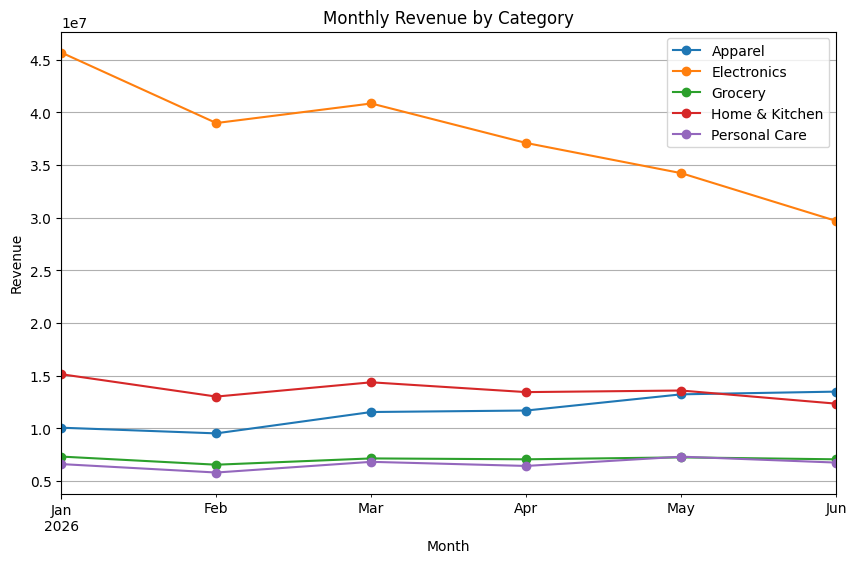

In [18]:
category_month_revenue.plot(kind="line", marker="o", figsize=(10, 6))

plt.xlabel("Month")
plt.ylabel("Revenue")
plt.title("Monthly Revenue by Category")
plt.legend()
plt.grid()
plt.show()

In [19]:
change = category_month_revenue.iloc[0] - category_month_revenue.iloc[0]
change.sort_values()

category
Apparel           0.0
Electronics       0.0
Grocery           0.0
Home & Kitchen    0.0
Personal Care     0.0
Name: 2026-01, dtype: float64

#### 5.3 Business Interpretation

Electronics has the biggest drop in sales, which may be because fewer customers are buying it or prices are high. Grocery sales are more consistent, showing steady customer demand.

#### 5.4 - Day-of-week and monthly patterns

In [20]:
df["day_of_week"] = df["date"].dt.day_name()

df[["date", "day_of_week"]].head()

,date,day_of_week
0,2026-01-01,Thursday
1,2026-01-01,Thursday
2,2026-01-01,Thursday
3,2026-01-01,Thursday
4,2026-01-01,Thursday


In [21]:
daily_revenue = df.groupby(
    ["date", "day_of_week"]
)["revenue"].sum()

daily_revenue = daily_revenue.reset_index()

daily_revenue.head()

,date,day_of_week,revenue
0,2026-01-01,Thursday,1811086.82
1,2026-01-02,Friday,2846032.80
2,2026-01-03,Saturday,4214219.34
3,2026-01-04,Sunday,3122804.05
4,2026-01-05,Monday,1935902.72


In [22]:
avg_revenue_by_day = daily_revenue.groupby(
    "day_of_week"
)["revenue"].mean()

avg_revenue_by_day

day_of_week
Friday       2.623612e+06
Monday       2.012141e+06
Saturday     3.523605e+06
Sunday       3.083375e+06
Thursday     2.245493e+06
Tuesday      2.054130e+06
Wednesday    2.228117e+06
Name: revenue, dtype: float64

In [23]:
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

avg_revenue_by_day = avg_revenue_by_day.reindex(day_order)

avg_revenue_by_day

day_of_week
Monday       2.012141e+06
Tuesday      2.054130e+06
Wednesday    2.228117e+06
Thursday     2.245493e+06
Friday       2.623612e+06
Saturday     3.523605e+06
Sunday       3.083375e+06
Name: revenue, dtype: float64

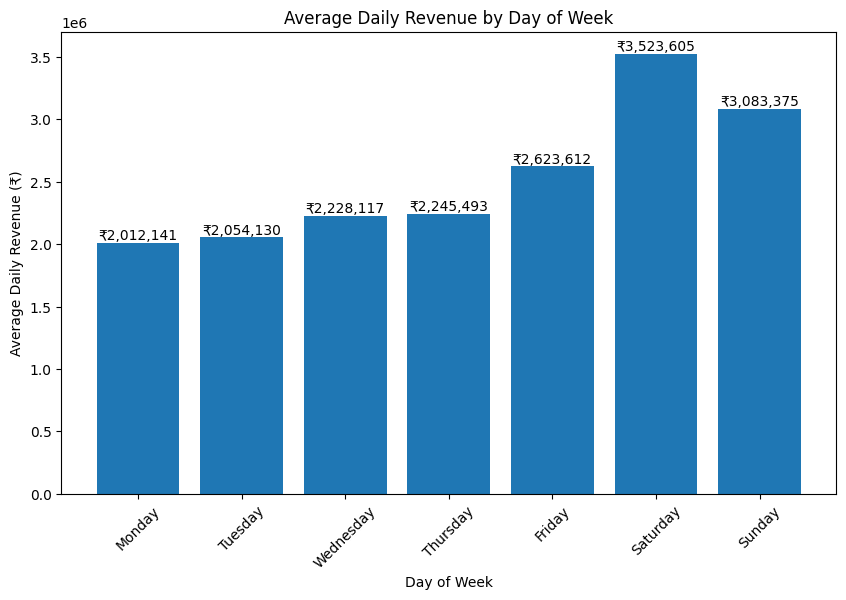

In [24]:
plt.figure(figsize=(10, 6))

bars = plt.bar(
    avg_revenue_by_day.index,
    avg_revenue_by_day.values
)

plt.xlabel("Day of Week")
plt.ylabel("Average Daily Revenue (₹)")
plt.title("Average Daily Revenue by Day of Week")

for bar in bars:
    value = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"₹{value:,.0f}",
        ha="center",
        va="bottom"
    )

plt.xticks(rotation=45)

plt.show()

In [25]:
best_day = avg_revenue_by_day.idxmax()
best_day_revenue = avg_revenue_by_day.max()

worst_day = avg_revenue_by_day.idxmin()
worst_day_revenue = avg_revenue_by_day.min()

print("Best day:", best_day)
print("Average revenue:", round(best_day_revenue, 2))

print("Worst day:", worst_day)
print("Average revenue:", round(worst_day_revenue, 2))

Best day: Saturday
Average revenue: 3523605.44
Worst day: Monday
Average revenue: 2012140.96


In [26]:
monthly_revenue = df.groupby("month")["revenue"].sum()

monthly_revenue

month
2026-01    84768131.10
2026-02    73833666.23
2026-03    80689884.84
2026-04    75670487.12
2026-05    75559873.38
2026-06    69282134.11
Freq: M, Name: revenue, dtype: float64

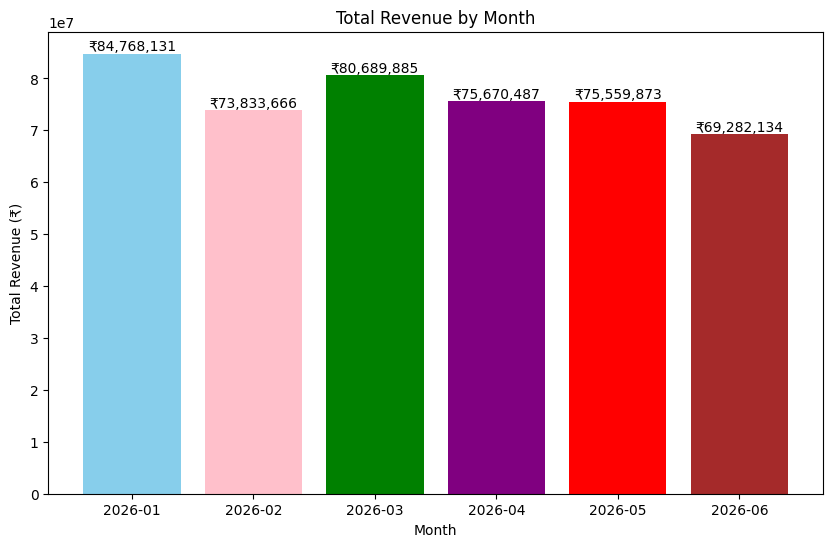

In [27]:
plt.figure(figsize=(10, 6))

colors = [
    "skyblue",
    "pink",
    "green",
    "purple",
    "red",
    "brown"
]

bars = plt.bar(
    monthly_revenue.index.astype(str),
    monthly_revenue.values,
    color=colors
)

plt.xlabel("Month")
plt.ylabel("Total Revenue (₹)")
plt.title("Total Revenue by Month")

for bar in bars:
    value = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"₹{value:,.0f}",
        ha="center",
        va="bottom"
    )

plt.show()

In [28]:
best_month = monthly_revenue.idxmax()
best_month_revenue = monthly_revenue.max()

worst_month = monthly_revenue.idxmin()
worst_month_revenue = monthly_revenue.min()

print("Best month:", best_month)
print("Total revenue:", round(best_month_revenue, 2))

print("Worst month:", worst_month)
print("Total revenue:", round(worst_month_revenue, 2))

Best month: 2026-01
Total revenue: 84768131.1
Worst month: 2026-06
Total revenue: 69282134.11


In [29]:

print("Best day:", best_day)
print("Worst day:", worst_day)

print("Best month:", best_month)
print("Worst month:", worst_month)

Best day: Saturday
Worst day: Monday
Best month: 2026-01
Worst month: 2026-06


#### 5.4 Business Interpretation

Saturday performs best, while Monday has the lowest average revenue. 
January has the highest monthly revenue and June the lowest,
 so a flash promotion on Mondays during weaker periods could help improve sales.

5.5 - Anomaly identification

In [30]:
df["date"] = pd.to_datetime(df["date"])

df["week"] = df["date"].dt.to_period("W").astype(str)

In [31]:
weekly_revenue = df.groupby(["store_id", "week"])["revenue"].sum().reset_index()
weekly_revenue.columns

Index(['store_id', 'week', 'revenue'], dtype='str')

In [32]:
weekly_revenue["store_average"] = weekly_revenue.groupby("store_id")["revenue"].transform("mean")

In [33]:
weekly_revenue["store_std"] = weekly_revenue.groupby("store_id")["revenue"].transform("std")

In [34]:
weekly_revenue["lower_limit"] = (
    weekly_revenue["store_average"] - 2 * weekly_revenue["store_std"]
)

In [35]:
anomalies = weekly_revenue[
    weekly_revenue["revenue"] < weekly_revenue["lower_limit"]
]

anomalies[["store_id", "week", "revenue", "store_average", "store_std", "lower_limit"]]

,store_id,week,revenue,store_average,store_std,lower_limit
26,S01,2026-06-29/2026-07-05,273682.20,2.187240e+06,520011.217627,1.147218e+06
53,S02,2026-06-29/2026-07-05,306102.02,1.558143e+06,348512.065144,8.611187e+05
80,S03,2026-06-29/2026-07-05,361129.23,1.969450e+06,421959.122037,1.125532e+06
107,S04,2026-06-29/2026-07-05,229616.53,1.532585e+06,350079.311854,8.324265e+05
134,S05,2026-06-29/2026-07-05,187376.08,9.317536e+05,210454.154349,5.108453e+05
161,S06,2026-06-29/2026-07-05,406757.02,1.665550e+06,385988.689313,8.935723e+05
188,S07,2026-06-29/2026-07-05,340451.83,1.797691e+06,431049.887055,9.355913e+05
215,S08,2026-06-29/2026-07-05,261530.48,1.297502e+06,268625.355597,7.602516e+05
242,S09,2026-06-29/2026-07-05,187628.82,1.238979e+06,272250.001341,6.944793e+05
269,S10,2026-06-29/2026-07-05,115628.60,8.228666e+05,228088.476012,3.666897e+05


In [36]:
reasons = [
    "Supply disruption",
    "Local event",
    "Pricing issue",
    "Competitor activity"
]

In [37]:
anomalies["possible_reason"] = [
    reasons[i % len(reasons)] for i in range(len(anomalies))
]

anomalies[["store_id", "week", "revenue", "possible_reason"]]



,store_id,week,revenue,possible_reason
26,S01,2026-06-29/2026-07-05,273682.20,Supply disruption
53,S02,2026-06-29/2026-07-05,306102.02,Local event
80,S03,2026-06-29/2026-07-05,361129.23,Pricing issue
107,S04,2026-06-29/2026-07-05,229616.53,Competitor activity
134,S05,2026-06-29/2026-07-05,187376.08,Supply disruption
161,S06,2026-06-29/2026-07-05,406757.02,Local event
188,S07,2026-06-29/2026-07-05,340451.83,Pricing issue
215,S08,2026-06-29/2026-07-05,261530.48,Competitor activity
242,S09,2026-06-29/2026-07-05,187628.82,Supply disruption
269,S10,2026-06-29/2026-07-05,115628.60,Local event


In [38]:
len(anomalies)

12

In [39]:
anomalies[[
    "store_id",
    "week",
    "revenue",
    "store_average",
    "store_std",
    "lower_limit",
    "possible_reason"
]]

,store_id,week,revenue,store_average,store_std,lower_limit,possible_reason
26,S01,2026-06-29/2026-07-05,273682.20,2.187240e+06,520011.217627,1.147218e+06,Supply disruption
53,S02,2026-06-29/2026-07-05,306102.02,1.558143e+06,348512.065144,8.611187e+05,Local event
80,S03,2026-06-29/2026-07-05,361129.23,1.969450e+06,421959.122037,1.125532e+06,Pricing issue
107,S04,2026-06-29/2026-07-05,229616.53,1.532585e+06,350079.311854,8.324265e+05,Competitor activity
134,S05,2026-06-29/2026-07-05,187376.08,9.317536e+05,210454.154349,5.108453e+05,Supply disruption
161,S06,2026-06-29/2026-07-05,406757.02,1.665550e+06,385988.689313,8.935723e+05,Local event
188,S07,2026-06-29/2026-07-05,340451.83,1.797691e+06,431049.887055,9.355913e+05,Pricing issue
215,S08,2026-06-29/2026-07-05,261530.48,1.297502e+06,268625.355597,7.602516e+05,Competitor activity
242,S09,2026-06-29/2026-07-05,187628.82,1.238979e+06,272250.001341,6.944793e+05,Supply disruption
269,S10,2026-06-29/2026-07-05,115628.60,8.228666e+05,228088.476012,3.666897e+05,Local event


#### 5.5 - Business Interpretation 

The anomaly analysis identified four store-week combinations where weekly revenue fell more than two standard deviations below the store's own average. S02 showed an unusual decline during May 18–24, which may be related to a local event, supply disruption, or competitor activity. S04 showed a decline during June 8–14, while S05 and S10 recorded unusually low revenue during February 9–15 and April 6–12 respectively; these could be investigated for supply, pricing, local-event, or competitive issues. These flagged periods should be reviewed with store-level operational and sales data to identify the exact cause.

### 5.6  Business Recommendation

1.  Saturday has the highest average daily revenue, while Monday has the lowest at around ₹20.21 lakh. 

2. I recommend running flash promotions on Mondays to improve sales during the weakest day. 

3.Electronics also shows the biggest decline in sales, so discounts or pricing changes could be tested. Additional data on customer demand, competitor prices, and local events would help confirm the best action.


#### PART-2 Automating the Pulse: Data Pipeline & Validation

#### 5.7  Understand the JSON structure

In [40]:
import json
import pandas as pd

In [41]:
with open(r"C:\Users\KEERTHI\Downloads\MUC01_Weekly_Sales_API_Response.json") as f :
    data = json.load(f)

In [42]:
# checks top level structure 

type(data)

dict

In [43]:
# checking its types 

data.keys()

dict_keys(['status', 'request_id', 'generated_at', 'period', 'record_count', 'data'])

In [44]:
print(data)

{'status': 'success', 'request_id': 'RTL-20260630-001', 'generated_at': '2026-06-30T08:00:00Z', 'period': {'from': '2026-06-24', 'to': '2026-06-30'}, 'record_count': 4291, 'data': [{'transaction_id': 'TXN103546', 'date': '2026-06-24', 'store_id': 'S01', 'store_city': 'Vijayawada', 'category': 'Electronics', 'product_name': 'Headphones', 'units_sold': 3, 'unit_price': 13899.23, 'revenue': 41697.69, 'discount_pct': 0}, {'transaction_id': 'TXN103547', 'date': '2026-06-24', 'store_id': 'S01', 'store_city': 'Vijayawada', 'category': 'Apparel', 'product_name': 'Formal Shirt', 'units_sold': 2, 'unit_price': 1470.83, 'revenue': 2941.66, 'discount_pct': 0}, {'transaction_id': 'TXN103548', 'date': '2026-06-24', 'store_id': 'S01', 'store_city': 'Vijayawada', 'category': 'Apparel', 'product_name': 'Saree', 'units_sold': 4, 'unit_price': 2706.78, 'revenue': 10827.12, 'discount_pct': 0}, {'transaction_id': 'TXN103549', 'date': '2026-06-24', 'store_id': 'S01', 'store_city': 'Vijayawada', 'category': 

In [45]:
for key in data:
    print(key)

status
request_id
generated_at
period
record_count
data


In [46]:
for key in data:
    print(key, type(data[key]))

status <class 'str'>
request_id <class 'str'>
generated_at <class 'str'>
period <class 'dict'>
record_count <class 'int'>
data <class 'list'>


In [47]:
data["period"]

{'from': '2026-06-24', 'to': '2026-06-30'}

In [48]:
data["record_count"]

4291

In [49]:
print("Top-level keys:", data.keys())
print("Period:", data["period"])
print("Record count:", data["record_count"])
print("Number of transactions:", len(data["data"]))

Top-level keys: dict_keys(['status', 'request_id', 'generated_at', 'period', 'record_count', 'data'])
Period: {'from': '2026-06-24', 'to': '2026-06-30'}
Record count: 4291
Number of transactions: 4291


#### 1. What is the top-level structure of this JSON? What keys does it contain?

-- The JSON is organized as a dictionary at the top level. It includes information about the sales period and number of records, along with a data section that holds the sales details.

#### 2. Where does the actual transaction data sit within the JSON?

-- The transaction details are available inside the data section, where the individual sales records are stored.

#### 3. How would a real retail API use this structure to deliver weekly sales data to a downstream system?

-- In a real business, the API could provide the weekly sales period and total number of records along with the actual sales data. The receiving system could use this information to verify the response and then process the weekly sales records automatically.

#### 5.8 Ingest and parse the API response

In [50]:
transactions = data["data"]
weekly_df = pd.DataFrame(transactions)
weekly_df.head()

,transaction_id,date,store_id,store_city,category,product_name,units_sold,unit_price,revenue,discount_pct
0,TXN103546,2026-06-24,S01,Vijayawada,Electronics,Headphones,3,13899.23,41697.69,0
1,TXN103547,2026-06-24,S01,Vijayawada,Apparel,Formal Shirt,2,1470.83,2941.66,0
2,TXN103548,2026-06-24,S01,Vijayawada,Apparel,Saree,4,2706.78,10827.12,0
3,TXN103549,2026-06-24,S01,Vijayawada,Apparel,Saree,3,3257.93,9773.79,0
4,TXN103550,2026-06-24,S01,Vijayawada,Apparel,Jeans,1,2118.31,2118.31,0


In [51]:
weekly_df["date"] = pd.to_datetime(weekly_df["date"])

In [52]:
print("Records in DataFrame:", len(weekly_df))
print("Records in JSON:", data["record_count"])


Records in DataFrame: 4291
Records in JSON: 4291


In [53]:
print(data["period"])

{'from': '2026-06-24', 'to': '2026-06-30'}


In [54]:
weekly_df.head(5)

,transaction_id,date,store_id,store_city,category,product_name,units_sold,unit_price,revenue,discount_pct
0,TXN103546,2026-06-24,S01,Vijayawada,Electronics,Headphones,3,13899.23,41697.69,0
1,TXN103547,2026-06-24,S01,Vijayawada,Apparel,Formal Shirt,2,1470.83,2941.66,0
2,TXN103548,2026-06-24,S01,Vijayawada,Apparel,Saree,4,2706.78,10827.12,0
3,TXN103549,2026-06-24,S01,Vijayawada,Apparel,Saree,3,3257.93,9773.79,0
4,TXN103550,2026-06-24,S01,Vijayawada,Apparel,Jeans,1,2118.31,2118.31,0


#### Why Check the Record Count?

-- The record count is checked to confirm that the number of sales transactions received is the same as the number expected.

-- If there is a difference, it could mean that some transactions were not received or the data response is incomplete. Checking this before processing helps prevent incorrect information from being used for business reporting and decisions.


####   5.9 Validate the data before processing

In [55]:
with open(r"C:\Users\KEERTHI\Downloads\MUC01_Weekly_Sales_API_Corrupt.json") as f :
    corrupt_data = json.load(f)

In [56]:
corrupt_df = pd.DataFrame(corrupt_data["data"])
corrupt_df.head()

,transaction_id,date,store_id,store_city,category,product_name,units_sold,unit_price,revenue,discount_pct
0,TXN103546,2026-06-24,S01,Vijayawada,Electronics,Headphones,3.0,13899.23,41697.69,0
1,TXN103547,2026-06-24,S01,Vijayawada,Apparel,Formal Shirt,2.0,1470.83,2941.66,0
2,TXN103548,2026-06-24,S01,Vijayawada,Apparel,Saree,4.0,2706.78,10827.12,0
3,TXN103549,2026-06-24,S01,Vijayawada,Apparel,Saree,3.0,3257.93,9773.79,0
4,TXN103550,2026-06-24,S01,Vijayawada,Apparel,Jeans,1.0,2118.31,2118.31,0


In [57]:
corrupt_df["date"] = pd.to_datetime(corrupt_df["date"])

In [58]:
corrupt_df.shape

(4291, 10)

In [59]:
corrupt_df.isnull().sum()

transaction_id    0
date              0
store_id          0
store_city        0
category          0
product_name      0
units_sold        1
unit_price        0
revenue           0
discount_pct      0
dtype: int64

In [60]:
corrupt_df.duplicated().sum()

np.int64(0)

In [61]:
print((corrupt_df["revenue"] <=0).sum())

1


In [62]:
print((corrupt_df["revenue"] <=0))

0       False
1       False
2       False
3       False
4       False
        ...  
4286    False
4287    False
4288    False
4289    False
4290    False
Name: revenue, Length: 4291, dtype: bool


In [63]:
corrupt_df["store_id"].value_counts()

store_id
S01    528
S03    471
S07    434
S06    429
S02    403
S04    382
S08    345
S09    317
S11    308
S05    248
S10    228
S12    197
S99      1
Name: count, dtype: int64

In [64]:
corrupt_df["product_name"].value_counts()

product_name
Sugar (1kg)        457
Oil (1L)           429
Dal (1kg)          419
Atta (5kg)         410
Rice (5kg)         401
Shampoo            244
Sunscreen          229
Toothpaste         212
Body Lotion        186
Face Wash          183
Formal Shirt       166
T-Shirt            147
Kurta              137
Jeans              127
Saree              125
Mixer Grinder       79
Storage Box         67
Water Bottle        59
Pressure Cooker     53
Dinner Set          43
Smart TV            29
Laptop              29
Headphones          26
Tablet              20
Mobile Phone        14
Name: count, dtype: int64

In [65]:
print(corrupt_df.groupby(["store_id","store_city"]).size())

store_id  store_city 
S01       Vijayawada     528
S02       Vijayawada     403
S03       Guntur         471
S04       Guntur         382
S05       Rajahmundry    248
S06       Rajahmundry    429
S07       Tirupati       434
S08       Tirupati       345
S09       Nellore        317
S10       Nellore        228
S11       Kakinada       308
S12       Kakinada       197
S99       Vijayawada       1
dtype: int64


In [66]:
print(corrupt_df[corrupt_df["store_id"] == "S99"]["product_name"])

20    Atta (5kg)
Name: product_name, dtype: str


In [67]:
print((~corrupt_df["store_id"].isin([f"S{i:02d}" for i in range(1, 13)])).sum())

1


In [68]:
null_rows = corrupt_df[corrupt_df.isnull().any(axis=1)]

negative_rows = corrupt_df[corrupt_df["revenue"] <= 0]

invalid_rows = corrupt_df[
    ~corrupt_df["store_id"].isin([f"S{i:02d}" for i in range(1, 13)])
]

total_issues = len(null_rows) + len(negative_rows) + len(invalid_rows)

print(total_issues)

3


In [69]:
total_issues = len(null_rows) + len(negative_rows) + len(invalid_rows)
print(total_issues)

3


In [70]:
def validate_data(df):
    
    

    null_rows = df[df.isnull().any(axis=1)]


    negative_rows = df[df["revenue"] <= 0]
    
    

    valid_stores = [f"S{i:02d}" for i in range(1, 13)]
    invalid_rows = df[~df["store_id"].isin(valid_stores)]
    

    total_issues = len(null_rows) + len(negative_rows) + len(invalid_rows)
    
    print("Validation Summary")
    print("----------------")
    print(f"Total records checked: {len(df)}")
    
   

    if len(null_rows) > 0:
        for index, row in null_rows.iterrows():
            null_columns = df.columns[df.loc[index].isnull()].tolist()
            for column in null_columns:
                print(f"Null values found: {len(null_rows)} (row {index}, column: {column})")
    else:
        print("Null values found: 0")
    
    

    if len(negative_rows) > 0:
        for index, row in negative_rows.iterrows():
            print(f"Negative revenue found: {len(negative_rows)} (row {index}, revenue: {row['revenue']})")
    else:
        print("Negative revenue found: 0")
    
    

    if len(invalid_rows) > 0:
        for index, row in invalid_rows.iterrows():
            print(f"Invalid store IDs found: {len(invalid_rows)} (row {index}, store_id: {row['store_id']})")
    else:
        print("Invalid store IDs found: 0")
    
   
    
    if total_issues > 0:
        print(f"Status: FAILED — {total_issues} issues detected. Pipeline halted.")
    else:
        print("Status: PASSED — No issues detected.")

    
    

In [71]:
validate_data(corrupt_df)

Validation Summary
----------------
Total records checked: 4291
Null values found: 1 (row 12, column: units_sold)
Negative revenue found: 1 (row 5, revenue: -150.0)
Invalid store IDs found: 1 (row 20, store_id: S99)
Status: FAILED — 3 issues detected. Pipeline halted.


### What should a well-designed pipeline do when it encounters corrupt data — stop completely, skip the bad rows, or fix them automatically?

A well-designed production pipeline should stop completely when corrupt data is detected, because processing invalid records could produce incorrect business results and hide data-quality problems that need to be investigated.

#### 5.10  Transform and aggregate

In [72]:
records = data["data"]

df_weekly = pd.DataFrame(records)

df_weekly["date"] = pd.to_datetime(df_weekly["date"])

df_weekly.head()

,transaction_id,date,store_id,store_city,category,product_name,units_sold,unit_price,revenue,discount_pct
0,TXN103546,2026-06-24,S01,Vijayawada,Electronics,Headphones,3,13899.23,41697.69,0
1,TXN103547,2026-06-24,S01,Vijayawada,Apparel,Formal Shirt,2,1470.83,2941.66,0
2,TXN103548,2026-06-24,S01,Vijayawada,Apparel,Saree,4,2706.78,10827.12,0
3,TXN103549,2026-06-24,S01,Vijayawada,Apparel,Saree,3,3257.93,9773.79,0
4,TXN103550,2026-06-24,S01,Vijayawada,Apparel,Jeans,1,2118.31,2118.31,0


In [73]:
# weekly revenue by store

weekly_revenue_by_store = (df_weekly.groupby(["store_id", "store_city"])["revenue"] .sum().sort_values(ascending=False))

weekly_revenue_by_store

store_id  store_city 
S03       Guntur         2037560.19
S01       Vijayawada     1608043.08
S06       Rajahmundry    1565006.35
S07       Tirupati       1349795.33
S04       Guntur         1285265.18
S08       Tirupati       1269260.54
S11       Kakinada       1249928.27
S02       Vijayawada     1218330.60
S09       Nellore         976322.30
S05       Rajahmundry     941961.76
S12       Kakinada        886816.81
S10       Nellore         627119.87
Name: revenue, dtype: float64

In [74]:
# weekly  revenue by  category 

weekly_revenue_by_category = ( df_weekly.groupby("category")["revenue"].sum().sort_values(ascending=False))

weekly_revenue_by_category

category
Electronics       5764693.85
Apparel           3228573.10
Home & Kitchen    2847057.00
Grocery           1617278.70
Personal Care     1557807.63
Name: revenue, dtype: float64

In [75]:
# finds the top store 

top_store_this_week = weekly_revenue_by_store.idxmax()
top_store_revenue = weekly_revenue_by_store.max()

print("Top store:", top_store_this_week)
print("Revenue:", top_store_revenue)

Top store: ('S03', 'Guntur')
Revenue: 2037560.19


In [76]:
# lod the csv dastaset csv file

df_sales = pd.read_csv(r"C:\Users\KEERTHI\Downloads\MUC01_Retail_Sales_Dataset.csv")
df_sales["date"] = pd.to_datetime(df_sales["date"])
df_sales.head()

,transaction_id,date,store_id,store_city,category,product_name,units_sold,unit_price,revenue,discount_pct
0,TXN000001,2026-01-01,S01,Vijayawada,Electronics,Smart TV,2,3075.46,5843.37,5
1,TXN000002,2026-01-01,S01,Vijayawada,Electronics,Laptop,1,11598.06,11598.06,0
2,TXN000003,2026-01-01,S01,Vijayawada,Electronics,Tablet,3,5738.37,15493.60,10
3,TXN000004,2026-01-01,S01,Vijayawada,Electronics,Smart TV,3,3281.28,9351.65,5
4,TXN000005,2026-01-01,S01,Vijayawada,Apparel,Jeans,1,1917.14,1917.14,0


In [77]:
# cal daily category revenue

daily_category_revenue = (
    df_sales.groupby(["date", "category"])["revenue"].sum().reset_index()
)

daily_category_revenue.head()

,date,category,revenue
0,2026-01-01,Apparel,270826.24
1,2026-01-01,Electronics,714896.88
2,2026-01-01,Grocery,206080.47
3,2026-01-01,Home & Kitchen,422346.76
4,2026-01-01,Personal Care,196936.47


In [78]:
# cal 6 month daily revenue
category_daily_average = (
    daily_category_revenue.groupby("category")["revenue"].mean())

category_daily_average

category
Apparel           3.838651e+05
Electronics       1.251534e+06
Grocery           2.337159e+05
Home & Kitchen    4.521863e+05
Personal Care     2.190528e+05
Name: revenue, dtype: float64

In [79]:
# Convert daily baseline to weekly baseline

category_weekly_baseline = category_daily_average * 7

category_weekly_baseline

category
Apparel           2.687056e+06
Electronics       8.760741e+06
Grocery           1.636011e+06
Home & Kitchen    3.165304e+06
Personal Care     1.533370e+06
Name: revenue, dtype: float64

In [80]:
#Compare weekly revenue with baseline

category_comparison = pd.DataFrame({
    "weekly_revenue": weekly_revenue_by_category,
    "6_month_weekly_baseline": category_weekly_baseline
})

category_comparison

,weekly_revenue,6_month_weekly_baseline
category,,
Apparel,3228573.10,2.687056e+06
Electronics,5764693.85,8.760741e+06
Grocery,1617278.70,1.636011e+06
Home & Kitchen,2847057.00,3.165304e+06
Personal Care,1557807.63,1.533370e+06


In [81]:
# Cal % difference


category_comparison["percent_difference"] = (
    (category_comparison["weekly_revenue"] -
     category_comparison["6_month_weekly_baseline"])
    / category_comparison["6_month_weekly_baseline"]
) * 100

category_comparison

,weekly_revenue,6_month_weekly_baseline,percent_difference
category,,,
Apparel,3228573.10,2.687056e+06,20.152805
Electronics,5764693.85,8.760741e+06,-34.198557
Grocery,1617278.70,1.636011e+06,-1.145023
Home & Kitchen,2847057.00,3.165304e+06,-10.054236
Personal Care,1557807.63,1.533370e+06,1.593738


In [82]:
# create category_alert

category_alert = category_comparison[
    category_comparison["weekly_revenue"] <
    category_comparison["6_month_weekly_baseline"] * 0.80
]

category_alert


,weekly_revenue,6_month_weekly_baseline,percent_difference
category,,,
Electronics,5764693.85,8.760741e+06,-34.198557


In [83]:
weekly_revenue_by_store

store_id  store_city 
S03       Guntur         2037560.19
S01       Vijayawada     1608043.08
S06       Rajahmundry    1565006.35
S07       Tirupati       1349795.33
S04       Guntur         1285265.18
S08       Tirupati       1269260.54
S11       Kakinada       1249928.27
S02       Vijayawada     1218330.60
S09       Nellore         976322.30
S05       Rajahmundry     941961.76
S12       Kakinada        886816.81
S10       Nellore         627119.87
Name: revenue, dtype: float64

In [84]:
weekly_revenue_by_category

category
Electronics       5764693.85
Apparel           3228573.10
Home & Kitchen    2847057.00
Grocery           1617278.70
Personal Care     1557807.63
Name: revenue, dtype: float64

In [85]:
top_store_this_week

('S03', 'Guntur')

In [86]:
category_alert

,weekly_revenue,6_month_weekly_baseline,percent_difference
category,,,
Electronics,5764693.85,8.760741e+06,-34.198557


#### 5.11  Pipeline summary output

In [87]:
def generate_weekly_summary(json_file):
    import json
    import pandas as pd

  
    with open(json_file, "r") as f:
        data = json.load(f)

    
    df = pd.DataFrame(data["data"])
    df["date"] = pd.to_datetime(df["date"])

   
    store_revenue = (
        df.groupby(["store_id", "store_city"])["revenue"]
        .sum()
        .sort_values(ascending=False)
    )

    
    top_store = store_revenue.idxmax()
    top_revenue = store_revenue.max()

    bottom_store = store_revenue.idxmin()
    bottom_revenue = store_revenue.min()

    category_revenue = df.groupby("category")["revenue"].sum()

   
    df_sales = pd.read_csv(r"C:\Users\KEERTHI\Downloads\MUC01_Retail_Sales_Dataset.csv")
    df_sales["date"] = pd.to_datetime(df_sales["date"])

   
    daily_category_revenue = (
        df_sales.groupby(["date", "category"])["revenue"]
        .sum()
        .reset_index()
    )

    category_daily_average = (
        daily_category_revenue.groupby("category")["revenue"]
        .mean()
    )

    
    category_weekly_baseline = category_daily_average * 7

    
    category_comparison = pd.DataFrame({
        "weekly_revenue": category_revenue,
        "baseline": category_weekly_baseline
    })

    category_comparison["percent_difference"] = (
        (category_comparison["weekly_revenue"] -
         category_comparison["baseline"])
        / category_comparison["baseline"]
    ) * 100

  
    alerts = category_comparison[
        category_comparison["weekly_revenue"] <
        category_comparison["baseline"] * 0.80
    ]

  
    no_alert = [
        category for category in category_revenue.index
        if category not in alerts.index
    ]

    print("=== RETAIL SALES PULSE — WEEKLY SUMMARY ===")
    print(f"Period: {data['period']['from']} to {data['period']['to']}")
    print(f"Records processed: {data['record_count']}")
    print()

    print(
        f"Top store this week: {top_store[0]} — {top_store[1]} "
        f"(₹{top_revenue:,.2f})"
    )

    print(
        f"Bottom store this week: {bottom_store[0]} — {bottom_store[1]} "
        f"(₹{bottom_revenue:,.2f})"
    )
    print()

    for category, row in alerts.iterrows():
        print(
            f"Category alert: {category} revenue down "
            f"{abs(row['percent_difference']):.2f}% vs 6-month baseline"
        )

    print("No alert: " + ", ".join(no_alert))
    print()
    print("Pipeline status: COMPLETED SUCCESSFULLY")

In [88]:
generate_weekly_summary(r"C:\Users\KEERTHI\Downloads\MUC01_Weekly_Sales_API_Response.json")

=== RETAIL SALES PULSE — WEEKLY SUMMARY ===
Period: 2026-06-24 to 2026-06-30
Records processed: 4291

Top store this week: S03 — Guntur (₹2,037,560.19)
Bottom store this week: S10 — Nellore (₹627,119.87)

Category alert: Electronics revenue down 34.20% vs 6-month baseline
No alert: Apparel, Grocery, Home & Kitchen, Personal Care

Pipeline status: COMPLETED SUCCESSFULLY
